# 126 · Threshold-free error breakdown
A run's saved eval predictions `p` (probabilities, 64×64, no threshold) are scored against each true object `T_k` (connected components of truth > 0.5). Every pixel goes to its nearest true object (Voronoi cell `V_k`). `m_k` = Σp over `V_k`, `A_k` = |T_k|, `c_k` = centroid of T_k, COM = p-weighted centroid over `V_k`, `D` = √(64²+64²).

Two numbers per error: **error rate (% of samples)** = % of samples over the threshold (default view), and **mean error (0 = perfect)** = average continuous score (not for Missing object). `SHOW` in the next cell switches the figures.

| error | per-object score | range | error if |
|---|---|---|---|
| Missing object | `m_k < MISS_FRAC·A_k` (MISS_FRAC = 0.2) | {0,1} | any object missing |
| Wrong location | `‖COM − c_k‖ / D` | [0,1] | > LOC_THR = 0.05 |
| ↳ mirrored | COM nearer a mirror of `c_k` (flip-x / flip-y / rot180 about box centre) than `c_k`, mirror ≥ LOC_THR·D from `c_k` | {0,1} | reported as % of wrong-location samples |
| Wrong scale | `|m_k − A_k| / (m_k + A_k)`, direction too small / too large | [0,1] | > SCALE_THR = 0.2 |
| Wrong shape | `1 − softIoU(T_k, p_k')`, `p_k'` = p on `V_k` moved to `c_k`, zoomed so mass = `A_k`; softIoU = Σmin/Σmax | [0,1] | > SHAPE_THR = 0.3 |
| Extra blob (per sample) | p mass farther than LOC_THR·D from every true object / total mass | [0,1] | > EXTRA_THR = 0.2 |

Location / scale / shape only for non-missing objects; a sample's mean error averages its objects, and the sample counts as an error if any of its objects is over the threshold. Empty-target samples get Extra blob only. ID / OOD = `EvalSummary.ID` / `.OOD`, pooled per sample.

In [1]:
# default is a single run: RUNS = ["base300-v1"]; saved outputs compare two
RUNS = ["base300-v1", "maskae-v2"]
EPOCH = None          # None = latest saved eval epoch per run
SHOW = "rate"         # "rate" = error rate (% of samples) | "mean" = mean error (Missing object always shows its rate)
MISS_FRAC, LOC_THR, SCALE_THR, SHAPE_THR, EXTRA_THR = 0.2, 0.05, 0.2, 0.3, 0.2
CACHE = "/tmp/claude-1000/-home-ethantu-workspace-good-vibrations/4f4d6cce-0580-4e8f-a7d6-b4086bb83fa1/scratchpad/nb126_cache"

In [2]:
import os, sys, pickle
os.environ["CUDA_VISIBLE_DEVICES"] = ""
from pathlib import Path
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from scipy import ndimage

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src9"))
from dataset import CATEGORIES
from callbacks import EvalSummary
from score import truth

H = W = 64
D = np.hypot(H, W)
CTR = np.array([(H - 1) / 2, (W - 1) / 2])
MIRRORS = {"flip-x": np.array([1, -1]), "flip-y": np.array([-1, 1]), "rot180": np.array([-1, -1])}  # (row, col) signs about CTR
RR, CC = np.mgrid[:H, :W].astype(np.float64)
METRICS = [("missing", "Missing object"), ("loc", "Wrong location"), ("scale", "Wrong scale"), ("shape", "Wrong shape"), ("extra", "Extra blob")]
RATE = {"missing": "missing", "loc": "r_loc", "scale": "r_scale", "shape": "r_shape", "extra": "r_extra"}  # per-sample 0/1 error column

def com(p): m = p.sum(); return np.array([(p * RR).sum() / m, (p * CC).sum() / m])

def soft_iou(a, b): return np.minimum(a, b).sum() / max(np.maximum(a, b).sum(), 1e-12)

def recenter(pk, c_pred, c_true, s):
    """pk moved so c_pred lands on c_true and zoomed by s about it: output o <- input c_pred + (o - c_true)/s"""
    return np.clip(ndimage.affine_transform(pk, np.full(2, 1 / s), offset=c_pred - c_true / s, order=1, cval=0.0), 0, 1)

def score(p, y):
    """p (H,W) probabilities, y (H,W) bool truth -> (sample dict, [object dicts])"""
    p = p.astype(np.float64)
    lab, n = ndimage.label(y)
    total = p.sum()
    if n == 0:
        return dict(n_obj=0, missing=np.nan, loc=np.nan, scale=np.nan, shape=np.nan, extra=float(total > 1e-8), mirrored=np.nan,
                    r_loc=np.nan, r_scale=np.nan, r_shape=np.nan, r_extra=float(total > 1e-8)), []
    dist = np.stack([ndimage.distance_transform_edt(lab != k) for k in range(1, n + 1)])  # (n,H,W) distance to object k
    cell = dist.argmin(0)
    extra = p[dist.min(0) > LOC_THR * D].sum() / total if total > 1e-8 else 0.0
    objs = []
    for k in range(n):
        T, pk = (lab == k + 1).astype(np.float64), p * (cell == k)
        m, A, c = pk.sum(), T.sum(), com(T)
        o = dict(obj=k, area=A, mass=m, missing=float(m < MISS_FRAC * A), loc=np.nan, mirrored=np.nan, mirror=None,
                 scale=np.nan, too_small=np.nan, shape=np.nan)
        if not o["missing"]:
            cp = com(pk)
            d_true = np.linalg.norm(cp - c)
            o["loc"] = d_true / D
            mir = {nm: CTR + sg * (c - CTR) for nm, sg in MIRRORS.items()}
            ok = {nm: mc for nm, mc in mir.items() if np.linalg.norm(mc - c) >= LOC_THR * D and np.linalg.norm(cp - mc) < d_true}
            o["mirrored"] = float(o["loc"] > LOC_THR and len(ok) > 0)
            if o["mirrored"]: o["mirror"] = min(ok, key=lambda nm: np.linalg.norm(cp - ok[nm]))
            o["scale"], o["too_small"] = abs(m - A) / (m + A), float(m < A)
            o["shape"] = 1 - soft_iou(T, recenter(pk, cp, c, np.sqrt(A / m)))
        objs.append(o)
    seen = [o for o in objs if not o["missing"]]
    mean = lambda k: float(np.mean([o[k] for o in seen])) if seen else np.nan
    anyf = lambda k, thr: float(any(o[k] > thr for o in seen))
    return dict(n_obj=n, missing=float(any(o["missing"] for o in objs)), loc=mean("loc"), scale=mean("scale"), shape=mean("shape"),
                extra=float(extra), mirrored=anyf("mirrored", 0.5), r_loc=anyf("loc", LOC_THR), r_scale=anyf("scale", SCALE_THR),
                r_shape=anyf("shape", SHAPE_THR), r_extra=float(extra > EXTRA_THR)), objs

Failed to load CPU gemm_4bit_forward from kernels-community: No module named 'kernels'. Please make sure you already `pip install kernels` and the kernels >= 0.11.1


In [3]:
CAT = {(b, s): c for b, cs in CATEGORIES.items() for c, ss in cs.items() for s in ss}
BOXES = list(CATEGORIES)
ID_CATS, OOD_CATS = list(EvalSummary.ID), list(EvalSummary.OOD)
OTHER_CATS = [c for c in dict.fromkeys(c for cs in CATEGORIES.values() for c in cs) if c not in ID_CATS + OOD_CATS]  # unseen-position, control, ...

def latest(run): return max(int(p.name[2:6]) for p in (ROOT / "runs" / run / "outputs_history/eval").rglob("ep*.pt"))

def load(pts, where):
    """score every sample in the saved batches; where(pt, experiment) -> (box, split, category)"""
    S, O = [], []
    for pt in pts:
        d = torch.load(pt, weights_only=False, map_location="cpu")
        P, info = d["mask_pred"].float().numpy(), d["info"]
        for i in range(len(P)):
            e = info["experiment"][i]
            key = dict(zip(("box", "split", "category"), where(pt, e)), experiment=e, sample_id=int(info["sample_id"][i]),
                       position_id=int(info["position_id"][i]), speaker=int(info["speaker"][i]))
            y = truth(e, key["sample_id"], key["position_id"], key["speaker"], H, W) > 0.5
            s, objs = score(P[i], y)
            S.append({**key, **s}); O += [{**key, **o} for o in objs]
    return pd.DataFrame(S), pd.DataFrame(O)

def compute(run, ep):
    """eval splits + the saved train-set eval (split = category = "train"; box from the experiment)"""
    f = Path(CACHE) / f"v3_{run}_ep{ep:04d}_m{MISS_FRAC}_l{LOC_THR}_s{SCALE_THR}_h{SHAPE_THR}_e{EXTRA_THR}.pkl"
    if f.exists(): return pickle.load(open(f, "rb"))
    hist = ROOT / "runs" / run / "outputs_history"
    S, O = load(sorted(hist.glob(f"eval/*/*/ep{ep:04d}-ba*.pt")), lambda pt, e: (pt.parent.parent.name, pt.parent.name, CAT.get((pt.parent.parent.name, pt.parent.name))))
    box_of = dict(zip(S.experiment, S.box))
    TS, TO = load(sorted(hist.glob(f"train/ep{ep:04d}-ba*.pt")), lambda pt, e: (box_of[e], "train", "train"))
    k = ["experiment", "sample_id", "position_id", "speaker"]
    dup = TS.duplicated(k)  # a batch file can be saved twice (mid-fit + post-fit train eval): keep each sample once
    TO = TO[TO.set_index(k).index.isin(TS[~dup].set_index(k).index)].drop_duplicates(k + ["obj"])
    out = pd.concat([S, TS[~dup]], ignore_index=True), pd.concat([O, TO], ignore_index=True)
    f.parent.mkdir(parents=True, exist_ok=True); pickle.dump(out, open(f, "wb"))
    return out

LABEL, DS, DO = {}, {}, {}
for run in RUNS:
    ep = EPOCH if EPOCH is not None else latest(run)
    LABEL[run] = f"{run}@{ep}"
    DS[run], DO[run] = compute(run, ep)
    s = DS[run]
    print(f"{LABEL[run]}: train {(s.category == 'train').sum()} · ID {s.category.isin(ID_CATS).sum()} · OOD {s.category.isin(OOD_CATS).sum()}"
          f" · other {s.category.isin(OTHER_CATS).sum()} · empty-target {(s.n_obj == 0).sum()} · 2+ objects {(s.n_obj >= 2).sum()}")

base300-v1@300: train 11219 · ID 2501 · OOD 1419 · other 752 · empty-target 181 · 2+ objects 1503
maskae-v2@300: train 11219 · ID 2501 · OOD 1419 · other 752 · empty-target 181 · 2+ objects 1503


In [4]:
"""sanity: p = truth scores 0 everywhere, p = 0 is a missing object; shape floor = truth shifted by 0.5 px"""
s0 = DS[RUNS[0]]
picks = pd.concat([s0[s0.n_obj == 1].sample(5, random_state=0), s0[s0.n_obj >= 2].head(5)])
for _, r in picks.iterrows():
    y = truth(r.experiment, r.sample_id, r.position_id, r.speaker, H, W) > 0.5
    sp, _ = score(y.astype(np.float32), y)
    assert all(abs(sp[k]) < 1e-6 for k, _ in METRICS) and all(sp[RATE[k]] == 0 for k, _ in METRICS), sp
    assert score(np.zeros((H, W)), y)[0]["missing"] == 1.0
print(f"perfect / empty prediction checks pass on {len(picks)} samples ({(picks.n_obj >= 2).sum()} with 2+ objects)")

floor = []
for _, r in s0[s0.n_obj > 0].iterrows():
    y = truth(r.experiment, r.sample_id, r.position_id, r.speaker, H, W) > 0.5
    floor += [o["shape"] for o in score(np.clip(ndimage.shift(y.astype(np.float64), (0, 0.5), order=1), 0, 1), y)[1]]
SHAPE_FLOOR = float(np.nanmedian(floor))
print(f"shape floor (truth shifted 0.5 px): median {SHAPE_FLOOR:.3f} · p90 {np.nanpercentile(floor, 90):.3f} over {len(floor)} objects")

perfect / empty prediction checks pass on 10 samples (5 with 2+ objects)


shape floor (truth shifted 0.5 px): median 0.161 · p90 0.203 over 17213 objects


In [5]:
RUN_COLOR = ["#3B6FB6", "#B04A5A", "#7A5FB0", "#2E8F83", "#C29237", "#555555"]
BOX_COLOR = {"gastro": "#3B6FB6", "plastic": "#E07B39", "cardboard": "#7A9E4E"}
TRAIN_COLOR = "#4C8C4A"
plt.rcParams.update({"font.size": 16, "xtick.labelsize": 14, "ytick.labelsize": 14, "axes.titlesize": 19, "axes.labelsize": 16})
# 6 panels: (title, column, kind); kind "rate" = always % of samples, "metric" = follows SHOW
PANELS = [("Missing object", "missing", "rate"), ("Wrong location", "loc", "metric"), ("Mirrored (% of wrong-location samples)", "mirrored", "rate"),
          ("Wrong scale", "scale", "metric"), ("Wrong shape", "shape", "metric"), ("Extra blob", "extra", "metric")]

def value(s, k, kind):
    if k == "mirrored": return 100 * s[s.r_loc == 1].mirrored.mean()
    if kind == "rate" or SHOW == "rate": return 100 * s[RATE[k]].mean()
    return s[k].mean()

def grid(title, groups, rot=0):
    """one 2x3 figure; groups = [[(tick label, samples DataFrame, color, hatch), ...], ...], a gap between groups"""
    pos, bars = [], []
    for g in groups:
        x0 = (pos[-1] + 1.6) if pos else 0
        for j, b in enumerate(g): pos.append(x0 + j); bars.append(b)
    fig, axes = plt.subplots(2, 3, figsize=(38, 19), constrained_layout=True)
    for ax, (name, k, kind) in zip(axes.flat, PANELS):
        vs = [value(s, k, kind) for _, s, _, _ in bars]
        for p, v, (_, _, color, hatch) in zip(pos, vs, bars):
            ax.bar(p, np.nan_to_num(v), 0.85, color=color, hatch=hatch, edgecolor="#222222", linewidth=0.4)
        rate = kind == "rate" or SHOW == "rate"
        top = 100 if rate else 1.15 * np.nanmax(vs + [1e-9])
        for p, v, (_, s, _, _) in zip(pos, vs, bars):
            if np.isnan(v): continue
            txt = f"{v:.0f}" if rate else f"{v:.3f}"
            if k == "mirrored": txt += f"\nn={int((s.r_loc == 1).sum())}"  # wrong-location samples behind the %
            ax.text(p, v + 0.01 * top, txt, ha="center", va="bottom", fontsize=12)
        ax.set_xticks(pos, [b[0] for b in bars], rotation=rot, ha="right" if rot else "center")
        ax.set_ylim(0, 1.12 * top); ax.set_title(name)
        ax.set_ylabel("error rate (% of samples)" if rate else "mean error (0 = perfect)")
        if k == "shape" and not rate: ax.axhline(SHAPE_FLOOR, color="k", ls=":", lw=1)
    fig.suptitle(title + ("" if SHOW == "rate" else f" · dotted = Wrong shape floor (truth shifted 0.5 px) {SHAPE_FLOOR:.3f}"), fontsize=22)
    plt.show()

def cat(s, c): return s[s.category == c] if isinstance(c, str) else s[s.category.isin(c)]

def mirrored(s): return 100 * s[s.r_loc == 1].mirrored.mean()

## A · per run, in depth

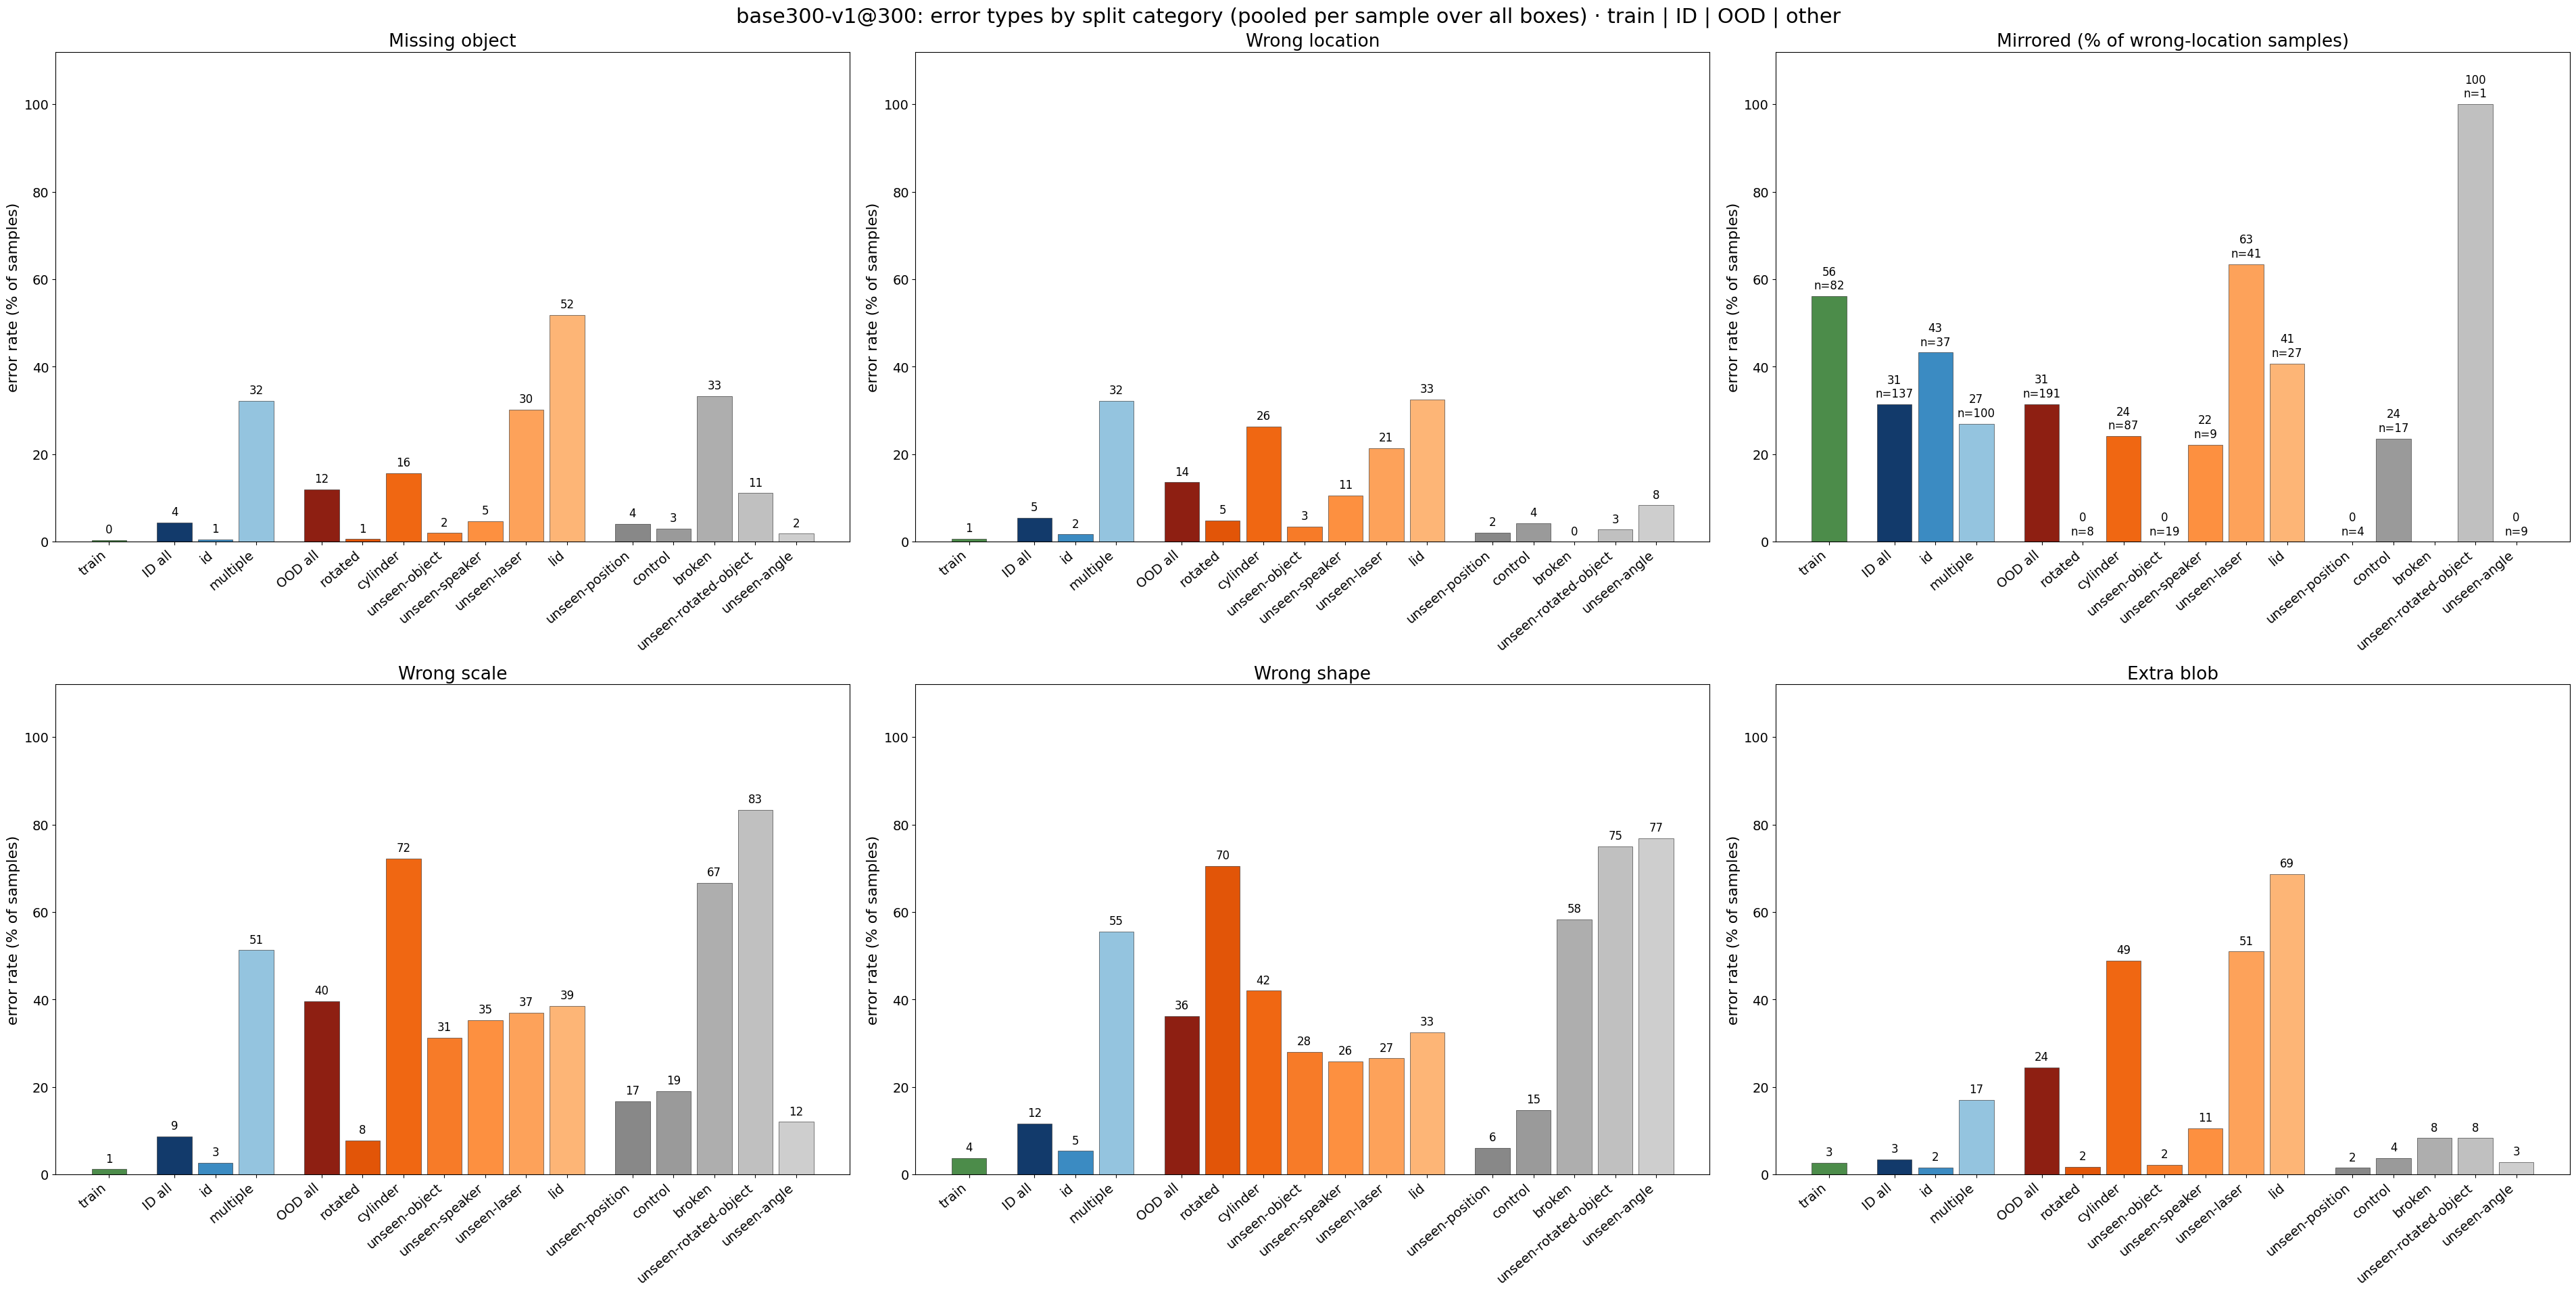

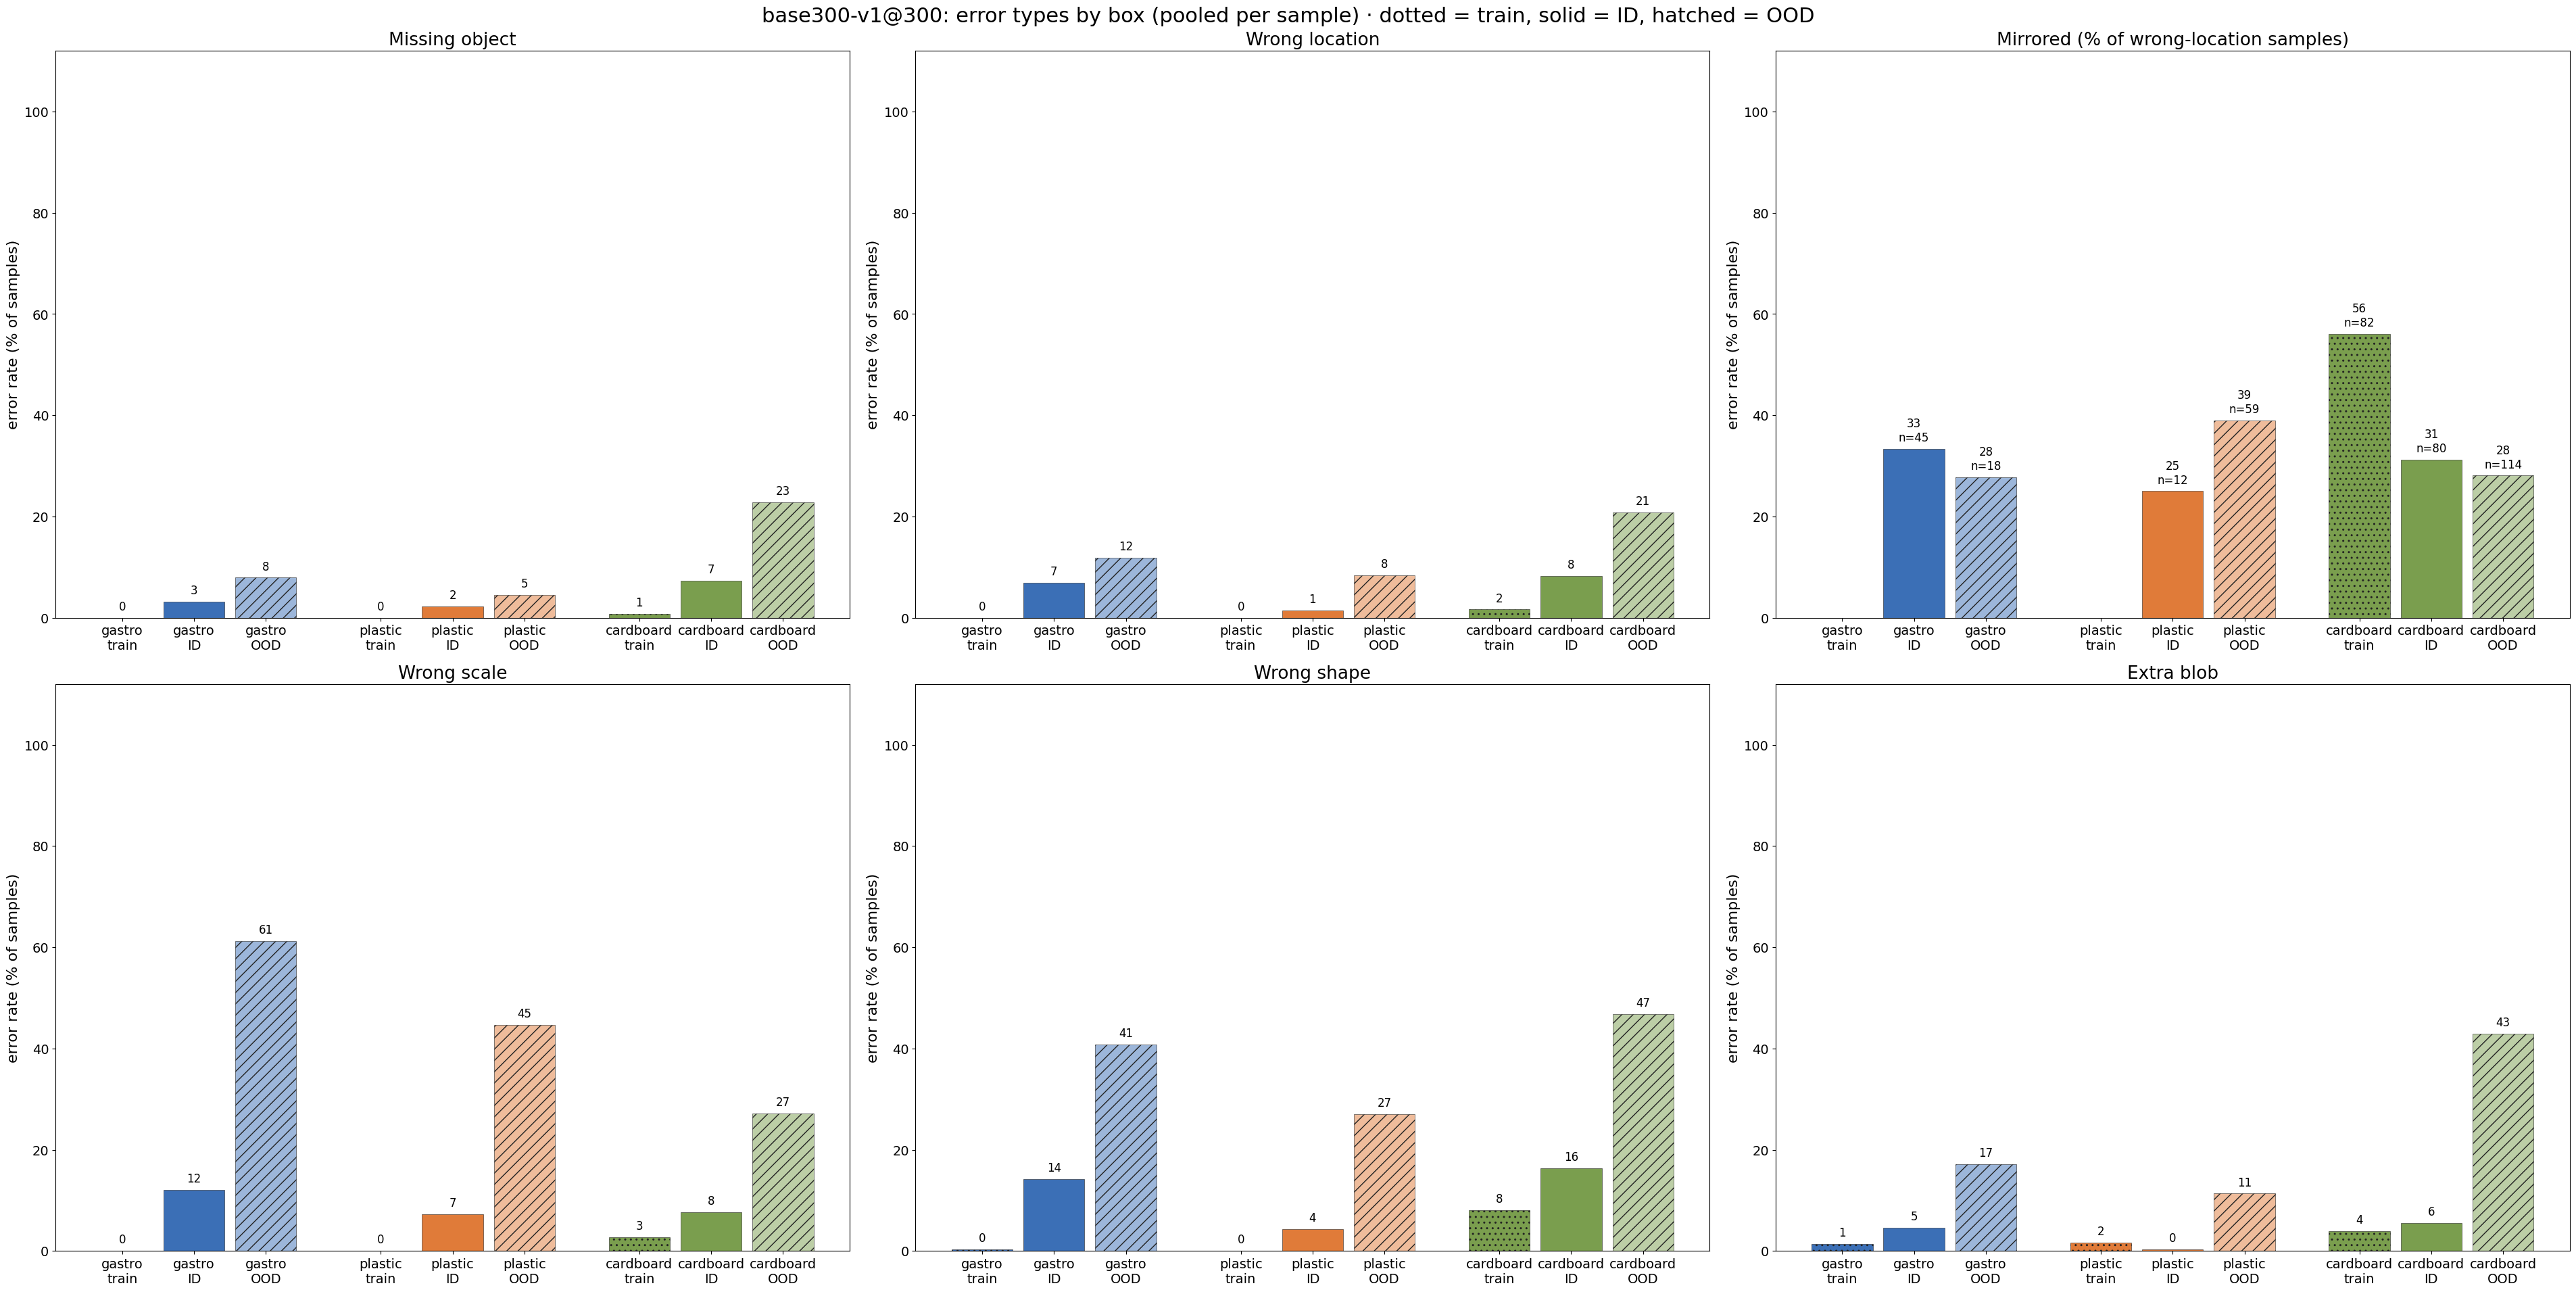

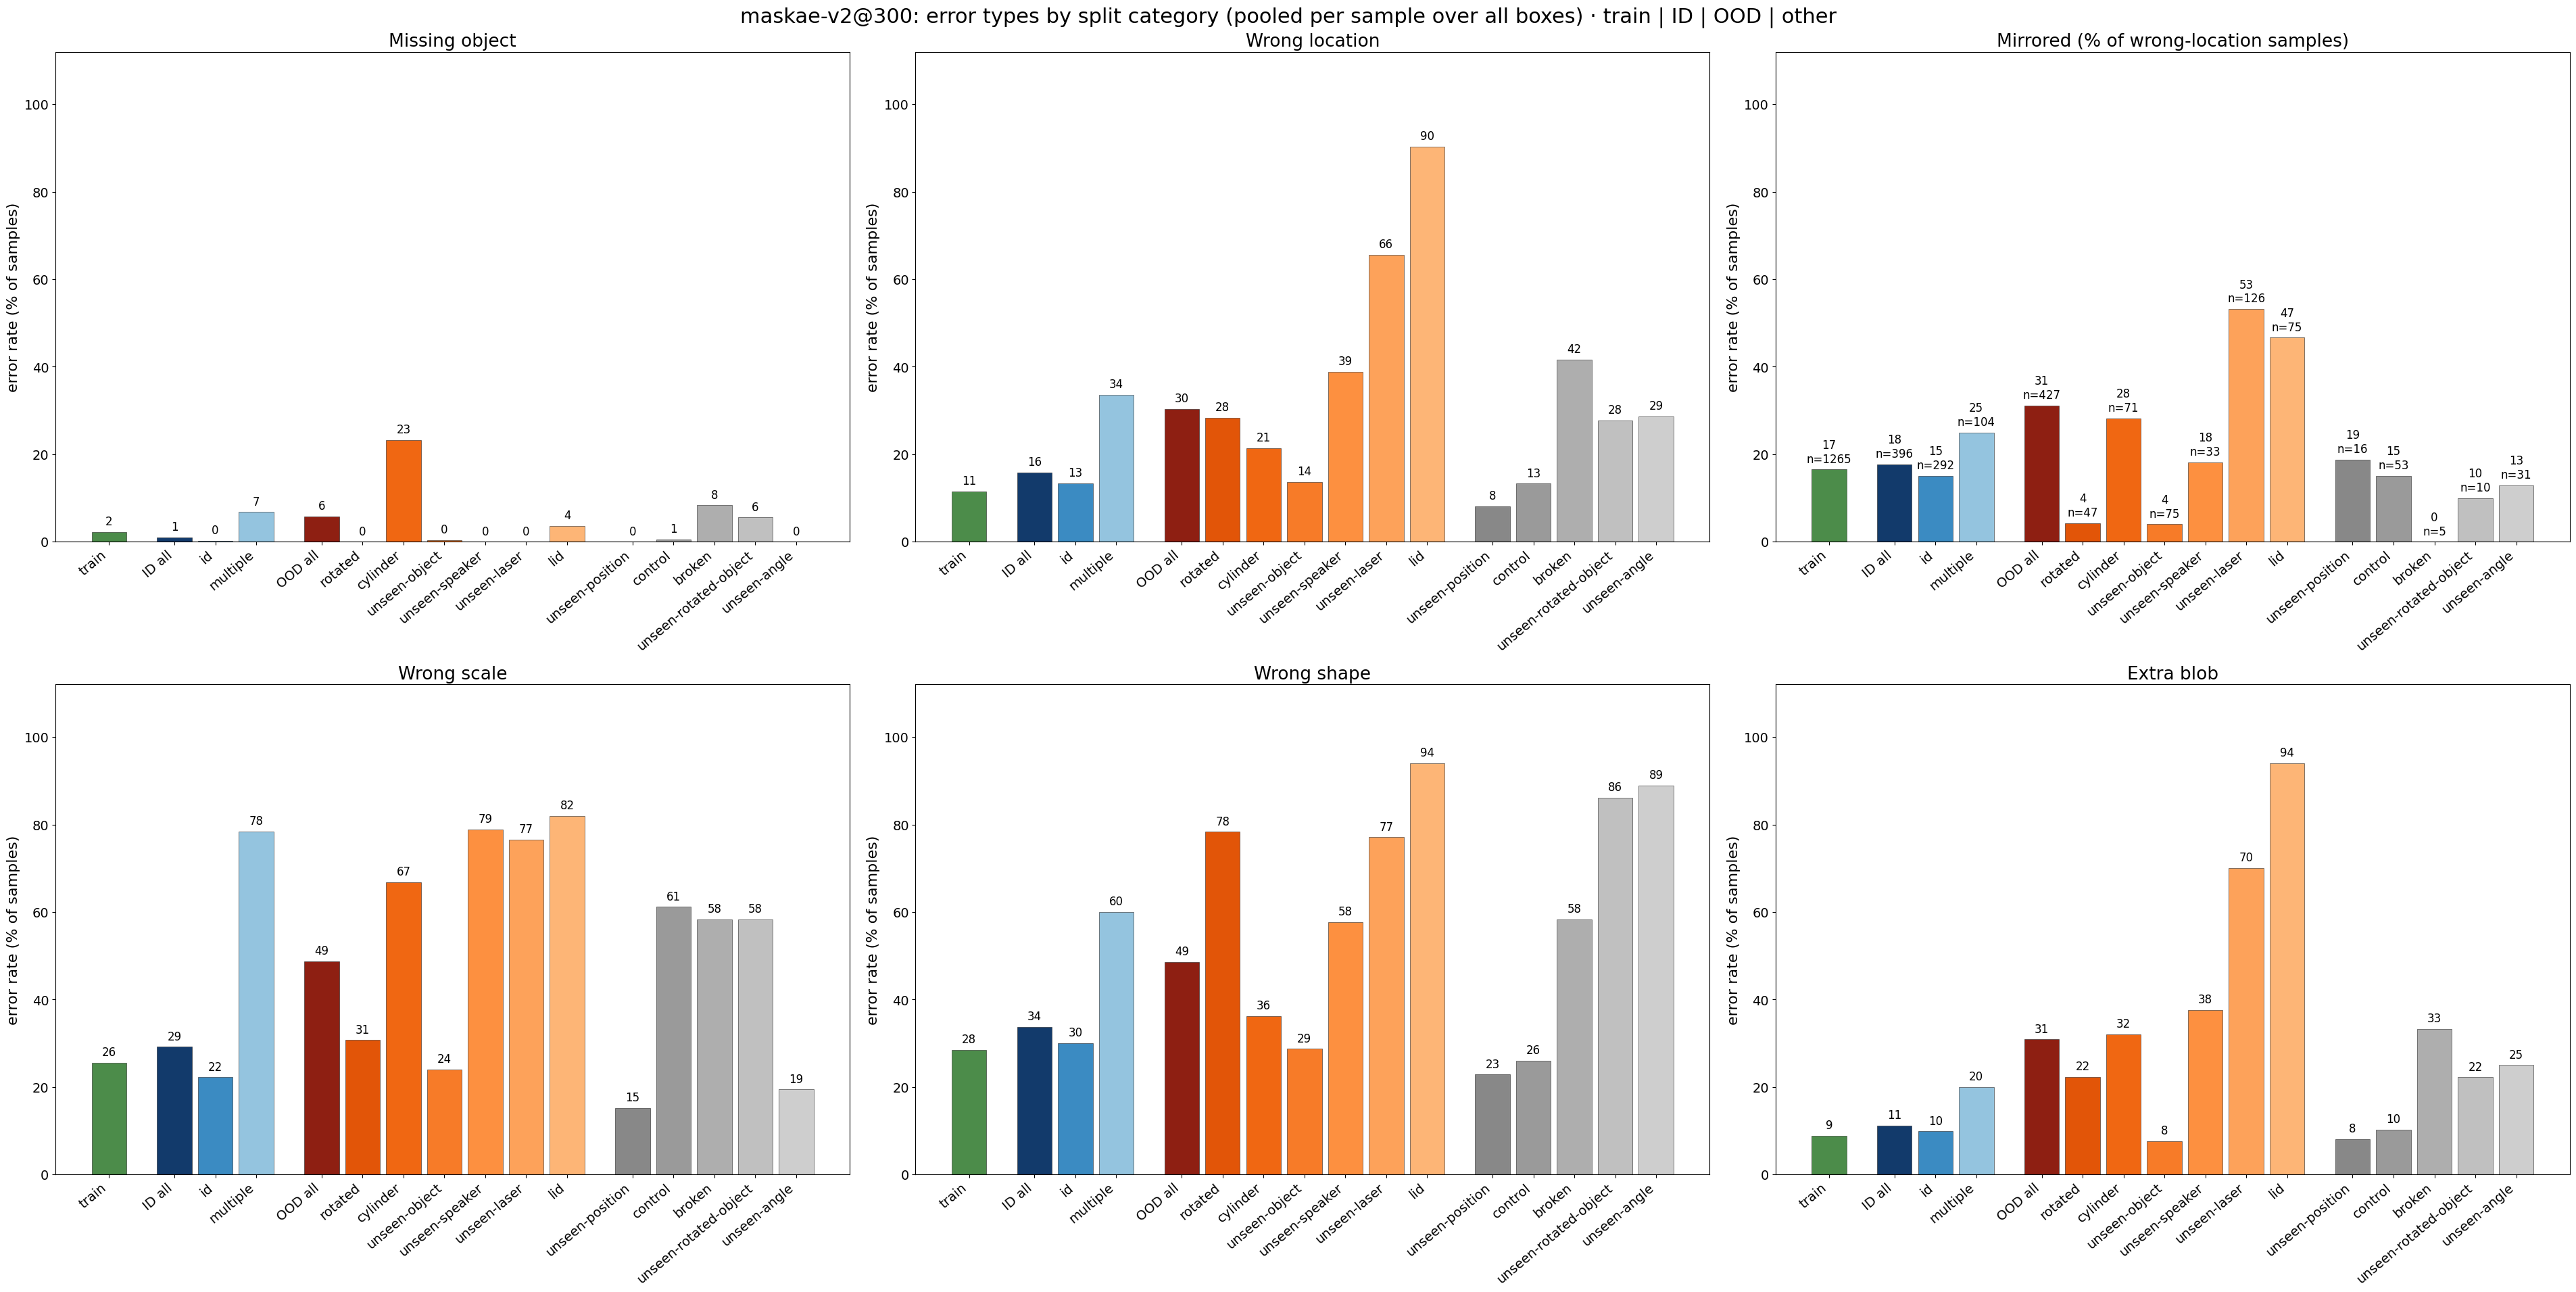

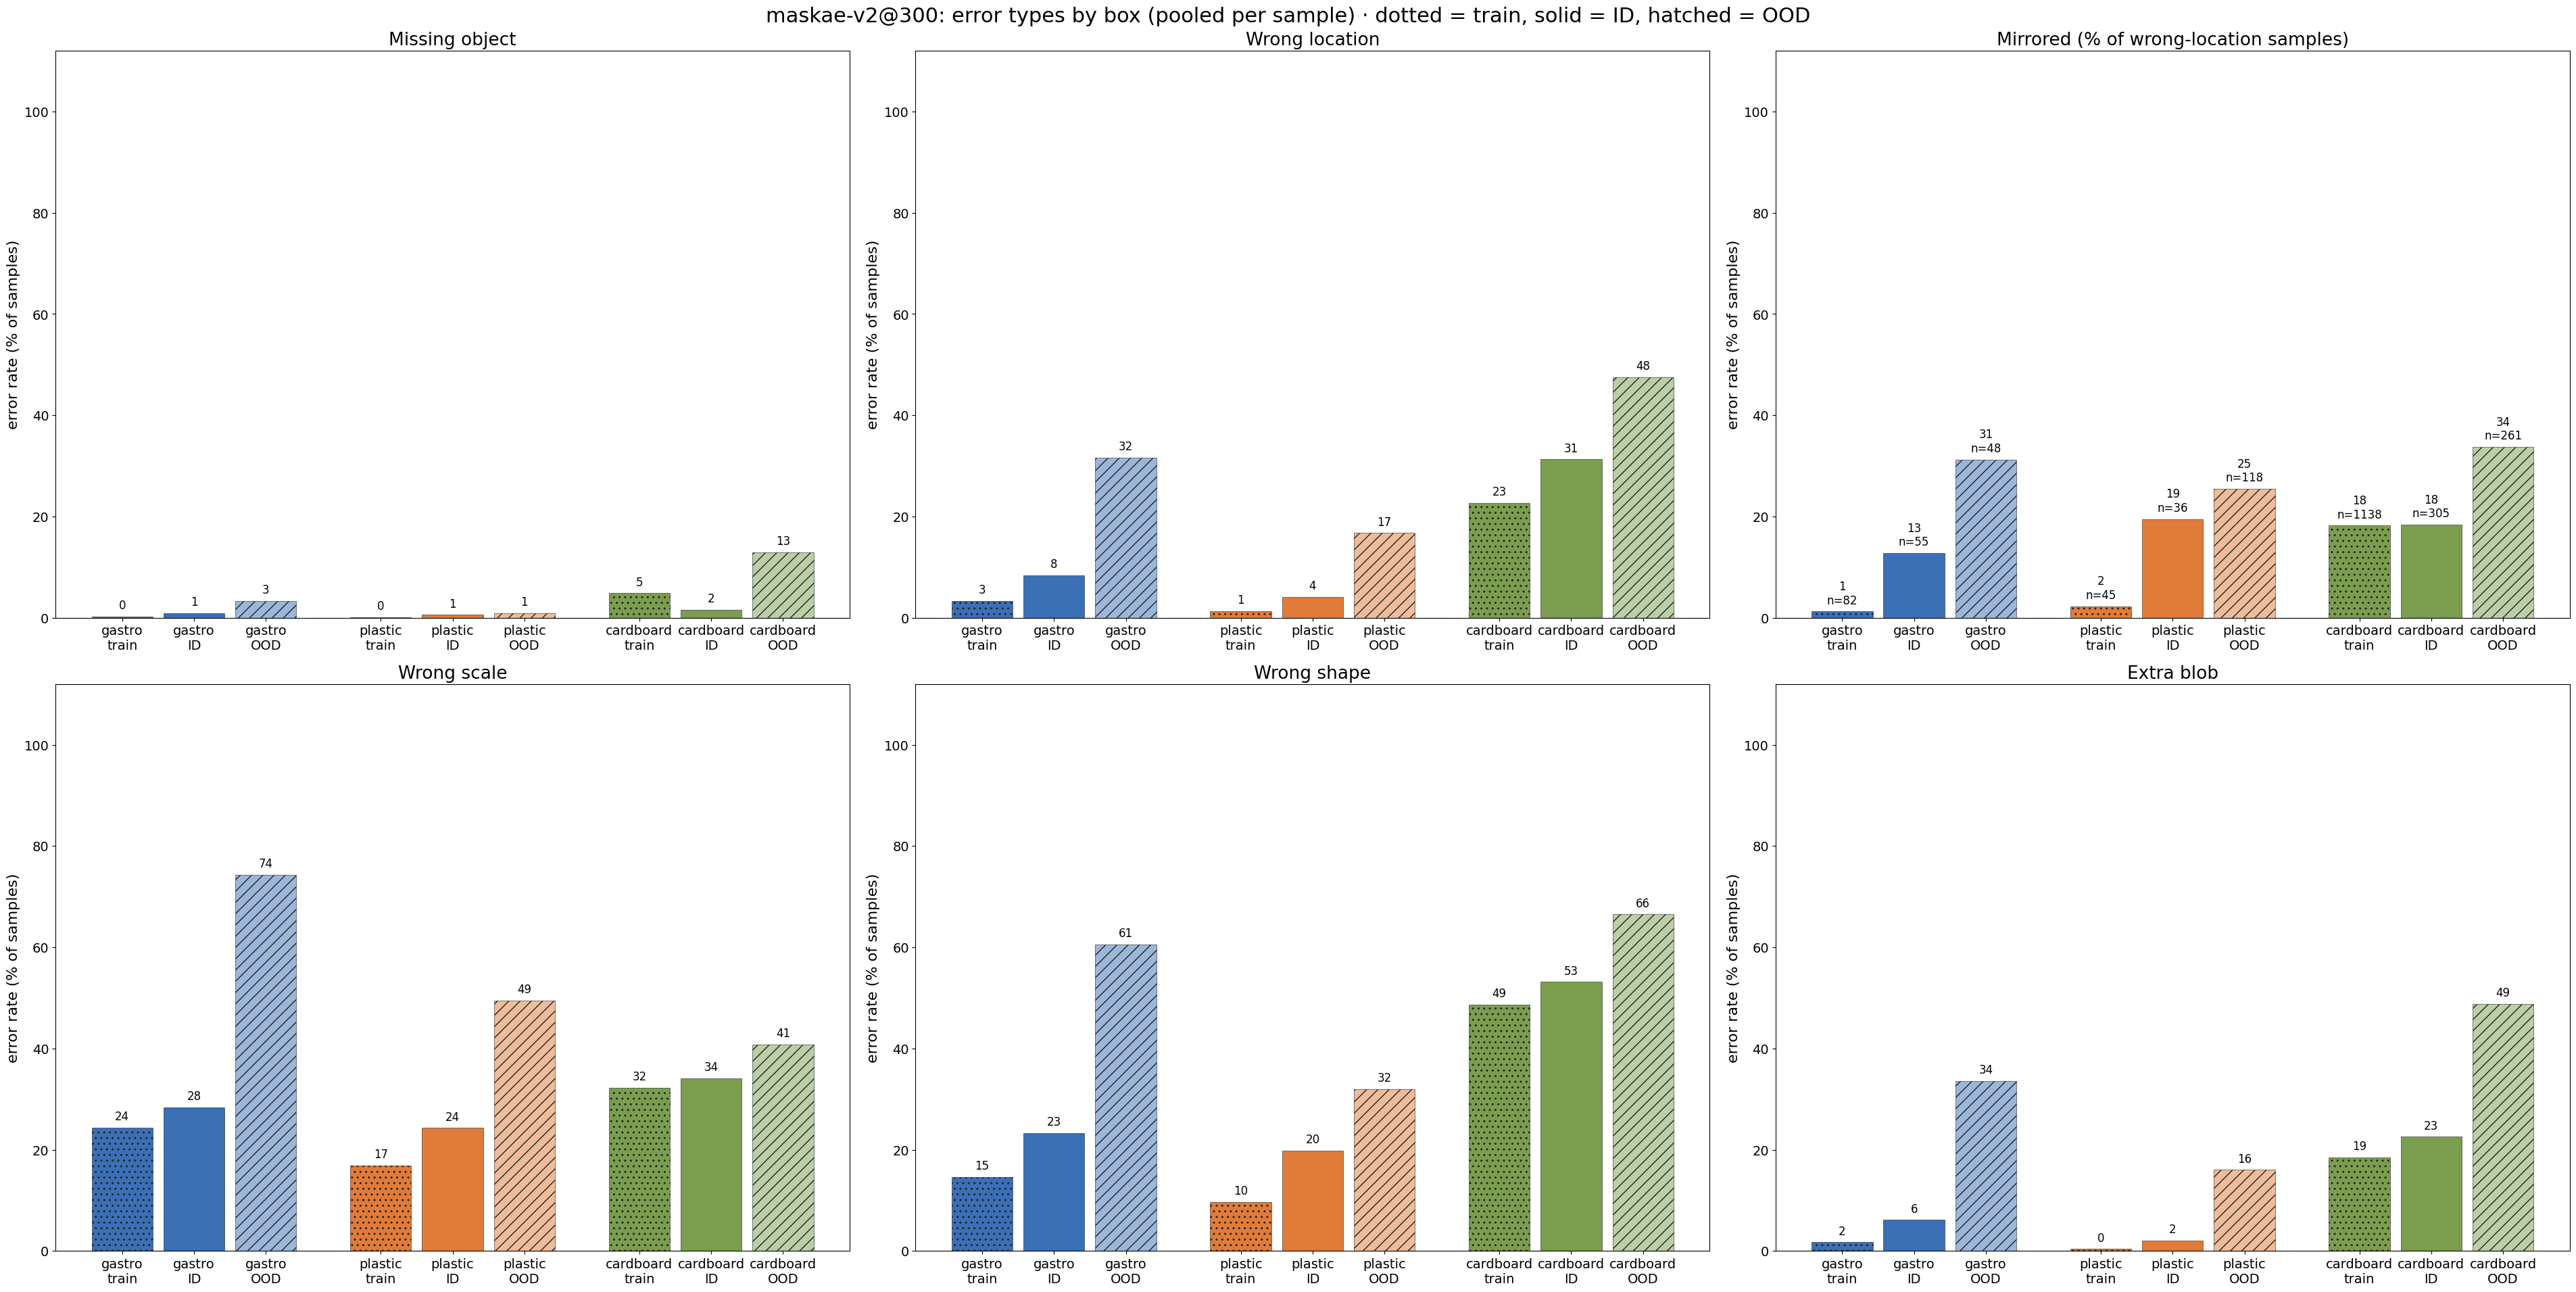

In [6]:
for run in RUNS:
    s = DS[run]
    blues, oranges, greys = plt.cm.Blues(np.linspace(0.65, 0.4, len(ID_CATS))), plt.cm.Oranges(np.linspace(0.7, 0.35, len(OOD_CATS))), plt.cm.Greys(np.linspace(0.55, 0.3, len(OTHER_CATS)))
    groups = [[("train", cat(s, "train"), TRAIN_COLOR, None)],
              [("ID all", cat(s, ID_CATS), "#123A6B", None)] + [(c, cat(s, c), col, None) for c, col in zip(ID_CATS, blues)],
              [("OOD all", cat(s, OOD_CATS), "#8E1F12", None)] + [(c, cat(s, c), col, None) for c, col in zip(OOD_CATS, oranges)],
              [(c, cat(s, c), col, None) for c, col in zip(OTHER_CATS, greys)]]
    grid(f"{LABEL[run]}: error types by split category (pooled per sample over all boxes) · train | ID | OOD | other", groups, rot=40)

    groups = [[(f"{b}\n{g}", cat(s[s.box == b], cs), BOX_COLOR[b] + a, h) for g, cs, a, h in (("train", "train", "FF", ".."), ("ID", ID_CATS, "FF", None), ("OOD", OOD_CATS, "80", "//"))]
              for b in BOXES]
    grid(f"{LABEL[run]}: error types by box (pooled per sample) · dotted = train, solid = ID, hatched = OOD", groups)

Per run: first grid = each category pooled per sample over all boxes (train = the saved train-set eval; other = neither ID nor OOD, e.g. unseen-position); second grid = train / ID / OOD per box. Missing object and Mirrored are always rates.

## B · runs compared

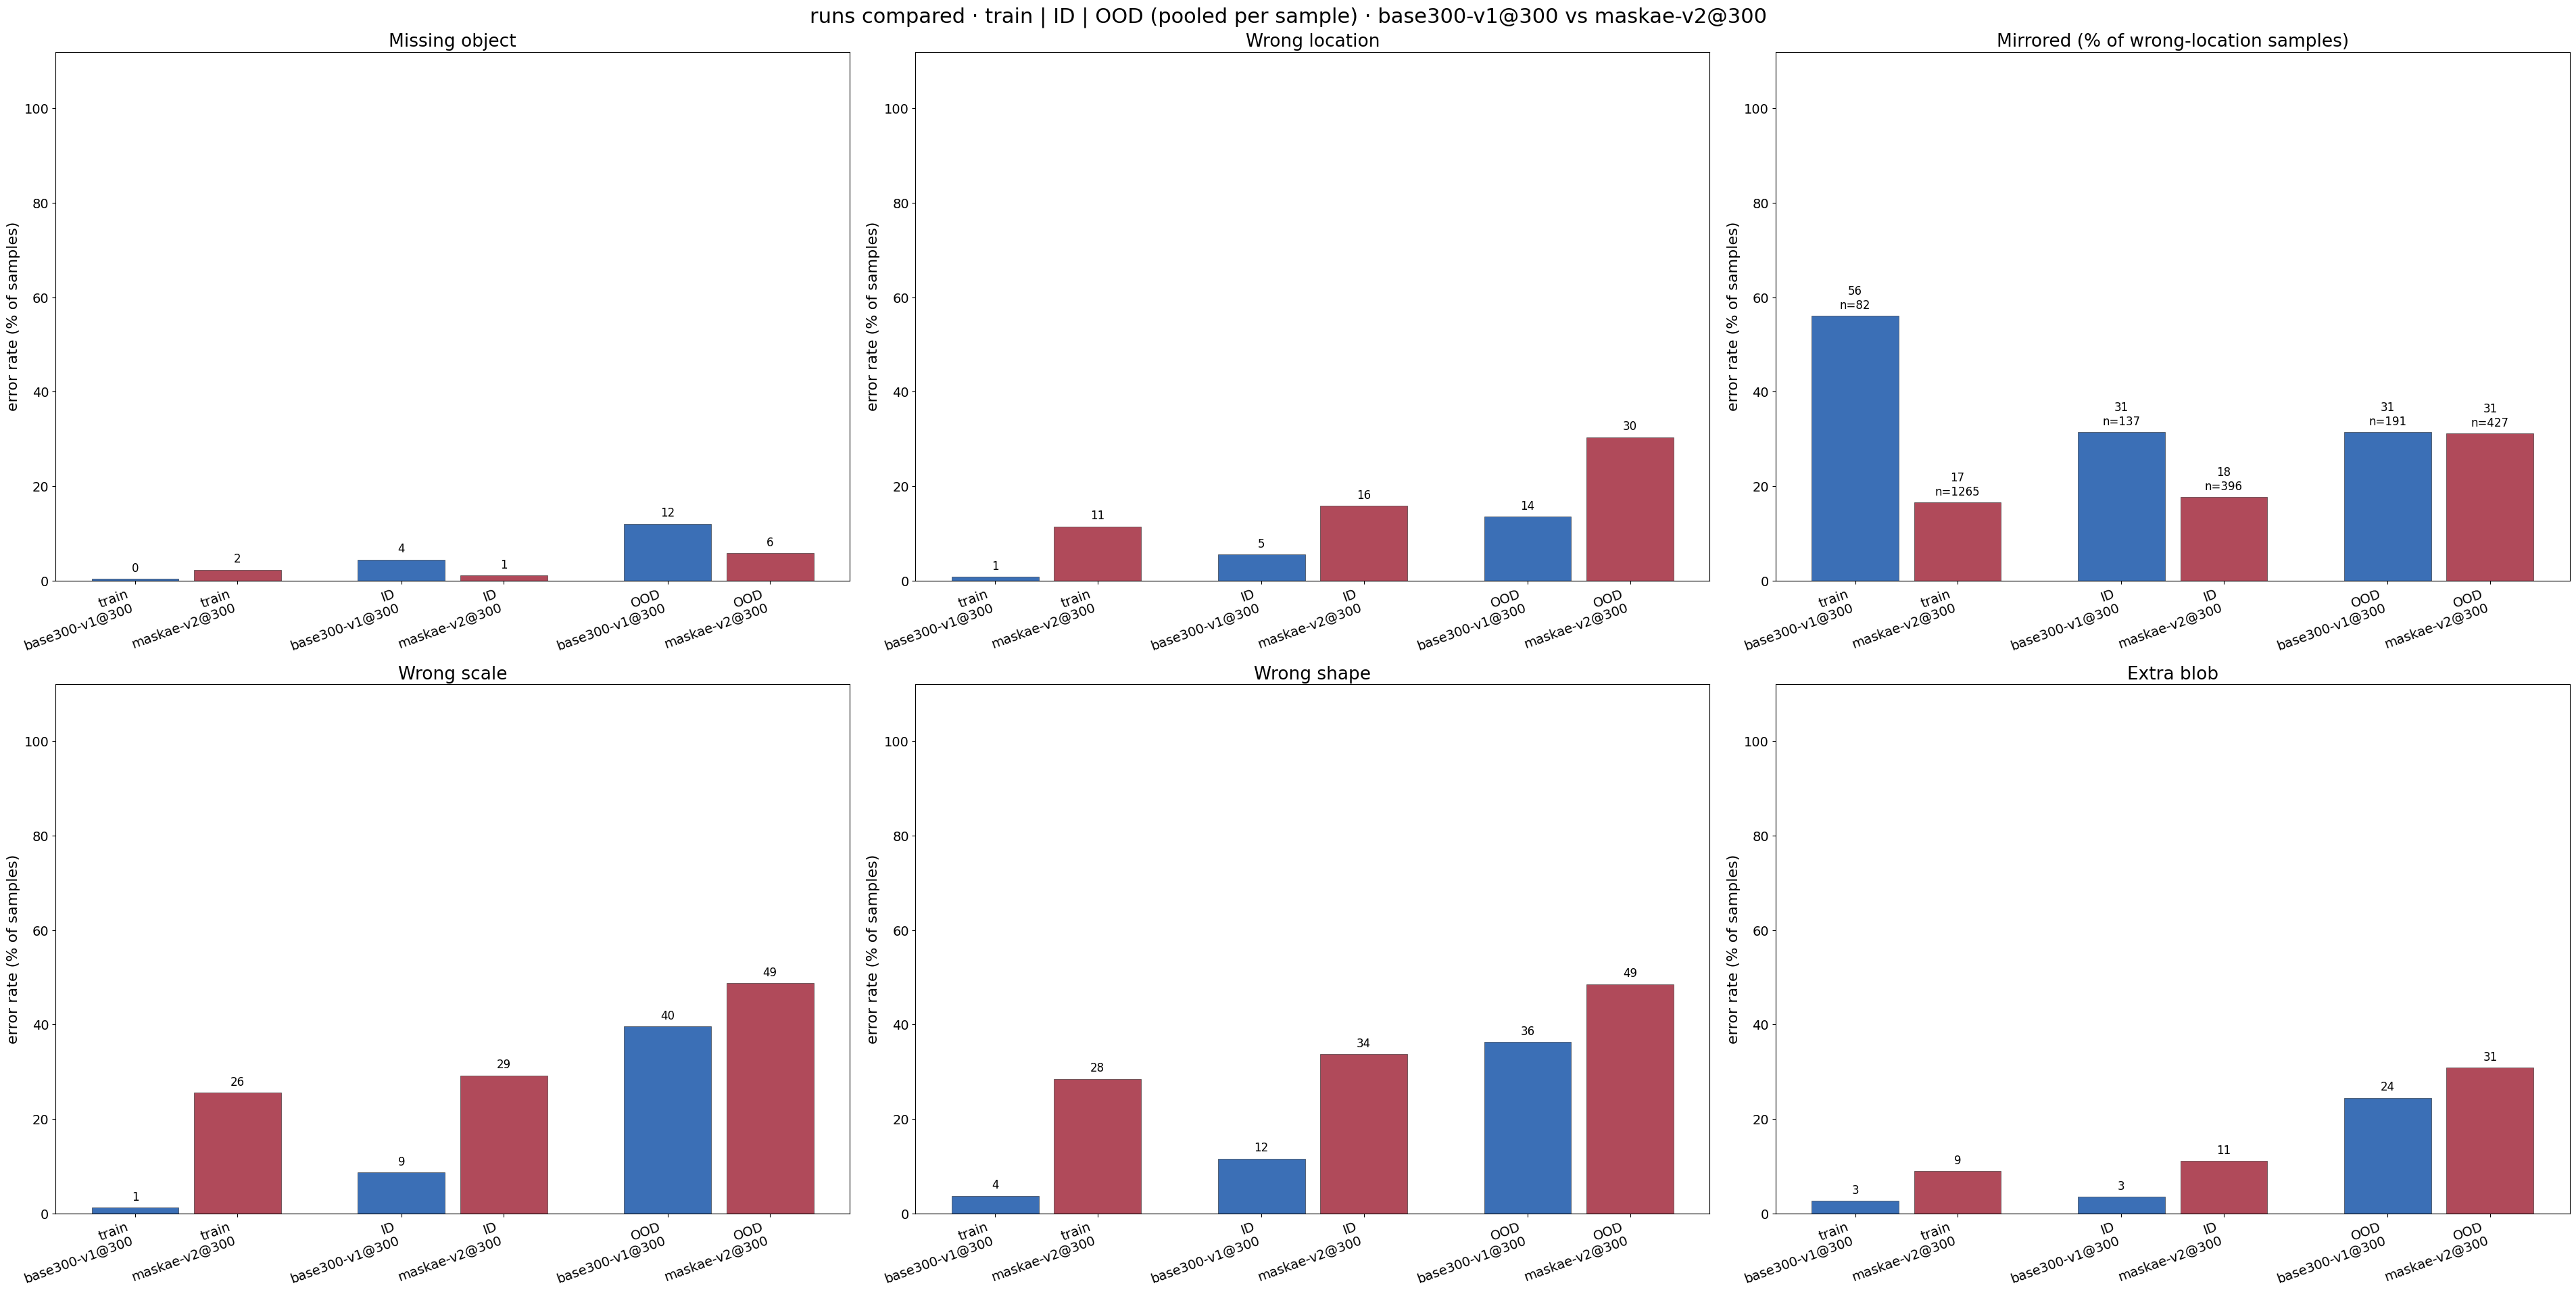

In [7]:
groups = [[(f"{g}\n{LABEL[r]}", cat(DS[r], cs), RUN_COLOR[i % len(RUN_COLOR)], None) for i, r in enumerate(RUNS)]
          for g, cs in (("train", "train"), ("ID", ID_CATS), ("OOD", OOD_CATS))]
grid("runs compared · train | ID | OOD (pooled per sample) · " + " vs ".join(LABEL[r] for r in RUNS), groups, rot=20)

One bar per run inside each of train / ID / OOD.

## Table

In [8]:
rows = []
for run in RUNS:
    for g, cats in (("train", ["train"]), ("ID", ID_CATS), ("OOD", OOD_CATS)):
        s, o = DS[run][DS[run].category.isin(cats)], DO[run][DO[run].category.isin(cats)]
        sf, mc = o[o.scale > SCALE_THR], o.mirror.value_counts()
        rows.append({"run": LABEL[run], "group": g, "n": len(s),
                     **{f"{n} · error rate %": round(100 * s[RATE[k]].mean(), 1) for k, n in METRICS},
                     **{f"{n} · mean error": round(s[k].mean(), 3) for k, n in METRICS if k != "missing"},
                     "mirrored (% of wrong-location samples)": round(mirrored(s), 1),
                     "wrong scale: too small %": round(100 * sf.too_small.mean(), 1), "wrong scale: too large %": round(100 * (1 - sf.too_small.mean()), 1),
                     **{f"mirror {m} (objects)": int(mc.get(m, 0)) for m in MIRRORS}})
TABLE = pd.DataFrame(rows).set_index(["run", "group"])
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
TABLE.T

run                                    base300-v1@300                     maskae-v2@300                    
group                                           train        ID       OOD         train        ID       OOD
n                                           11219.000  2501.000  1419.000     11219.000  2501.000  1419.000
Missing object · error rate %                   0.400     4.400    12.000         2.300     1.000     5.800
Wrong location · error rate %                   0.700     5.500    13.600        11.400    15.800    30.300
Wrong scale · error rate %                      1.200     8.700    39.600        25.600    29.200    48.800
Wrong shape · error rate %                      3.700    11.600    36.200        28.500    33.700    48.500
Extra blob · error rate %                       2.600     3.500    24.500         8.900    11.100    30.900
Wrong location · mean error                     0.005     0.016     0.038         0.025     0.029     0.067
Wrong scale · mean error                        0.032     0.068     0.250         0.134     0.142     0.275
Wrong shape · mean error                        0.161     0.201     0.339         0.294     0.315     0.454
Extra blob · mean error                         0.026     0.021     0.203         0.054     0.058     0.215
mirrored (% of wrong-location samples)         56.100    31.400    31.400        16.500    17.700    31.100
wrong scale: too small %                       41.000    77.600    49.600         7.400    10.400    18.500
wrong scale: too large %                       59.000    22.400    50.400        92.600    89.600    81.500
mirror flip-x (objects)                         8.000    12.000    19.000        58.000    18.000    30.000
mirror flip-y (objects)                        26.000    32.000    23.000       128.000    45.000    53.000
mirror rot180 (objects)                        12.000     0.000    18.000        23.000     7.000    50.000

Too small / too large is over wrong-scale objects; mirror counts are objects (flip-x = column mirrored, flip-y = row mirrored).